# 04 · MLP Centralisé — Version GPU Optimisée (Anti-Déséquilibre)

> **Problème** : Le MLP baseline atteint F1 macro=0.64 vs 0.86 pour RF/XGBoost.
> La cause est le déséquilibre extrême (Normal Traffic ~83%, Bots <0.1%).

> **Solution** : 3 stratégies anti-déséquilibre + exploitation GPU GTX 1650 Ti.

| Section | Contenu |
|---|---|
| A | MLP Multi-classe — 3 versions (balanced / focal / combined) |
| B | MLP Binaire — même approche, sauvegarde pour FL |
| C | Comparaison complète RF / XGBoost / MLP |

In [8]:
import os
import tensorflow as tf
import numpy as np

# Reproducibilité
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

# Configuration GPU 1650 Ti — exploiter à fond
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        # Memory growth — TF prend ce qu'il utilise, peut grandir jusqu'aux 4 GB
        tf.config.experimental.set_memory_growth(gpus[0], True)

        # Mixed precision FP16 — 2x speed sur Turing (compute capability 7.5)
        tf.keras.mixed_precision.set_global_policy('mixed_float16')

        # XLA JIT compilation — fusion d'opérations
        tf.config.optimizer.set_jit(True)

        print(f'✅ GPU configuré : {gpus[0].name}')
        print('✅ Mixed precision FP16 (Turing)')
        print('✅ XLA JIT compilation activé')
    except RuntimeError as e:
        print(f'⚠️ {e}')
else:
    print('⚠️ Pas de GPU détecté — fallback CPU')

# Optimisation allocation mémoire
os.environ['TF_GPU_ALLOCATOR'] = 'cuda_malloc_async'

✅ GPU configuré : /physical_device:GPU:0
✅ Mixed precision FP16 (Turing)
✅ XLA JIT compilation activé


## Pourquoi ces optimisations GPU ?

### Mixed Precision FP16
Le GTX 1650 Ti (Turing, compute capability 7.5) dispose de **Tensor Cores** capables
d'effectuer des multiplications matricielles en FP16 avec accumulation FP32.
En pratique : **2× plus rapide** sur les opérations Dense/BatchNorm, division par 2
de la mémoire VRAM utilisée par les activations. L'output layer garde `dtype='float32'`
pour éviter les instabilités numériques dans la softmax/sigmoid.

### XLA JIT Compilation
XLA (Accelerated Linear Algebra) fusionne les opérations du graphe de calcul en kernels
CUDA optimisés. Gain typique : 10-30% sur des modèles avec BN+Dropout répétés.

### Memory Growth
Sans cette option, TensorFlow réserve **toute** la VRAM (4 GB) dès le démarrage.
Avec `memory_growth=True`, il alloue dynamiquement — permet de coexister avec le
driver Windows/WSL2 qui réserve aussi une portion.

### BATCH_SIZE = 1024
Un batch plus grand → meilleure utilisation des CUDA cores, gradient plus stable.
La 1650 Ti supporte ~1024 samples×11 features en FP16 sans OOM (≈0.09 MB/batch).

In [9]:
import sys
import json
import time
import warnings
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import joblib
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, precision_recall_curve, average_precision_score,
)
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers, models, regularizers, callbacks

# ── Project root ──────────────────────────────────────────────────────
PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from federated_learning.preprocessing import load_splits, FeatureScaler

# ── Paths ─────────────────────────────────────────────────────────────
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
MODELS_DIR    = PROJECT_ROOT / 'models'
IMAGES_DIR    = PROJECT_ROOT / 'docs' / 'images'
LOGS_DIR      = PROJECT_ROOT / 'logs'
IMAGES_DIR.mkdir(parents=True, exist_ok=True)
LOGS_DIR.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings('ignore', category=FutureWarning)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('tab10')

BATCH_SIZE = 1024  # GTX 1650 Ti — exploite GPU sans OOM
print('✅  Imports OK')

✅  Imports OK


## 1 · Chargement des données & visualisation du déséquilibre

Le déséquilibre de classes est la **cause principale** de la sous-performance du MLP.
Avant toute correction, visualisons l'ampleur du problème.

02:47:05  DEBUG         train.npz loaded  |  X shape (1764525, 11)
02:47:05  DEBUG         val.npz loaded  |  X shape (252075, 11)
02:47:05  DEBUG         test.npz loaded  |  X shape (504151, 11)
02:47:05  INFO      ✅  All splits loaded from data/processed/
Train  : (1764525, 11)  |  Val : (252075, 11)  |  Test : (504151, 11)
Classes (7) : ['Bots', 'Brute Force', 'DDoS', 'DoS', 'Normal Traffic', 'Port Scanning', 'Web Attacks']


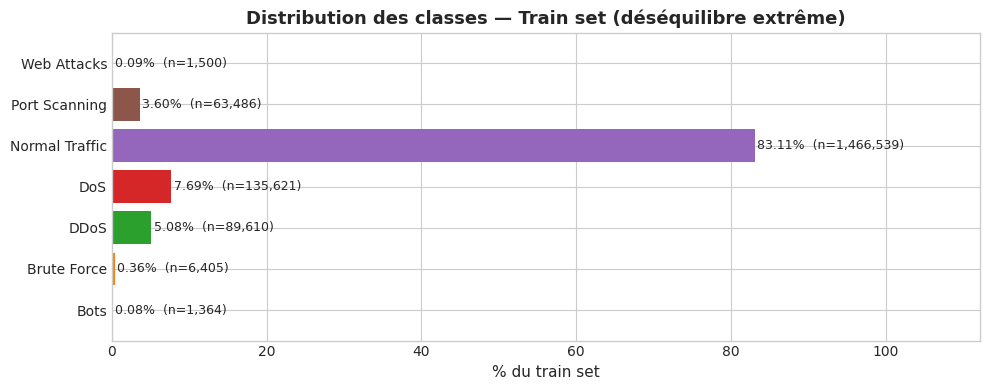

💾  mlp_class_distribution.png


In [10]:
splits = load_splits(PROCESSED_DIR)

X_train = splits['train']['X']
X_val   = splits['val']['X']
X_test  = splits['test']['X']

y_train_multi  = splits['train']['y_multi']
y_val_multi    = splits['val']['y_multi']
y_test_multi   = splits['test']['y_multi']

y_train_binary = splits['train']['y_binary']
y_val_binary   = splits['val']['y_binary']
y_test_binary  = splits['test']['y_binary']

label_encoder = joblib.load(MODELS_DIR / 'label_encoder.joblib')
CLASS_NAMES   = list(label_encoder.classes_)
N_CLASSES     = len(CLASS_NAMES)
INPUT_DIM     = X_train.shape[1]

print(f'Train  : {X_train.shape}  |  Val : {X_val.shape}  |  Test : {X_test.shape}')
print(f'Classes ({N_CLASSES}) : {CLASS_NAMES}')

# ── Class distribution bar chart ──────────────────────────────────────
unique, counts = np.unique(y_train_multi, return_counts=True)
pcts = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh([CLASS_NAMES[i] for i in unique], pcts,
               color=sns.color_palette('tab10', N_CLASSES))
for bar, pct, cnt in zip(bars, pcts, counts):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{pct:.2f}%  (n={cnt:,})', va='center', fontsize=9)
ax.set_xlabel('% du train set', fontsize=11)
ax.set_title('Distribution des classes — Train set (déséquilibre extrême)',
             fontsize=13, fontweight='bold')
ax.set_xlim(0, max(pcts) * 1.35)
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'mlp_class_distribution.png', dpi=150)
plt.show()
print('💾  mlp_class_distribution.png')

## 2 · FIX 1 — Class Weights

La stratégie `'balanced'` calcule `n_samples / (n_classes × n_samples_per_class)`.
Résultat attendu : **Normal Traffic ~0.20** (surreprésenté) et
**Bots / Web Attacks > 100** (ultra-minoritaires).
Keras multiplie la loss de chaque sample par le poids de sa classe,
forçant le modèle à traiter chaque classe de façon égale.

In [4]:
class_weights_array = compute_class_weight(
    'balanced',
    classes=np.unique(y_train_multi),
    y=y_train_multi
)
class_weight_dict = dict(enumerate(class_weights_array))

print('Class weights par classe :')
for idx, weight in class_weight_dict.items():
    cls = CLASS_NAMES[idx]
    print(f'  {cls:<25} (classe {idx}) : {weight:.2f}')

# Binary class weights (pour Section B)
binary_weights_array = compute_class_weight(
    'balanced', classes=np.array([0, 1]), y=y_train_binary
)
binary_weight_dict = dict(enumerate(binary_weights_array))
print(f'\nBinary weights : Normal={binary_weight_dict[0]:.3f}, Attack={binary_weight_dict[1]:.3f}')

Class weights par classe :
  Bots                      (classe 0) : 184.81
  Brute Force               (classe 1) : 39.36
  DDoS                      (classe 2) : 2.81
  DoS                       (classe 3) : 1.86
  Normal Traffic            (classe 4) : 0.17
  Port Scanning             (classe 5) : 3.97
  Web Attacks               (classe 6) : 168.05

Binary weights : Normal=0.602, Attack=2.961


## 3 · FIX 2 — Architecture MLP Profonde

L'architecture passe de 3 à **4 couches cachées** (256→128→64→32), avec
`BatchNorm` **entre** le `Dense` et l'`Activation` (ordre recommandé par He et al., 2016).
La régularisation L2 est plus forte sur les premières couches (0.001) et plus légère
sur les dernières (0.0005), évitant le sur-apprentissage sur les classes majoritaires.
Le `dtype='float32'` sur la couche de sortie est **obligatoire** avec mixed precision
pour éviter les NaN dans la softmax.

In [5]:
def build_deep_mlp(input_dim, n_classes, dropout_rate=0.4):
    inputs = layers.Input(shape=(input_dim,))

    # Couche 1 — large
    x = layers.Dense(256, kernel_regularizer=regularizers.l2(0.001))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(dropout_rate)(x)

    # Couche 2
    x = layers.Dense(128, kernel_regularizer=regularizers.l2(0.001))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(dropout_rate)(x)

    # Couche 3
    x = layers.Dense(64, kernel_regularizer=regularizers.l2(0.0005))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(dropout_rate * 0.75)(x)

    # Couche 4
    x = layers.Dense(32)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(dropout_rate * 0.5)(x)

    # Output float32 obligatoire avec mixed precision
    if n_classes == 2:
        outputs = layers.Dense(1, activation='sigmoid', dtype='float32')(x)
    else:
        outputs = layers.Dense(n_classes, activation='softmax', dtype='float32')(x)

    return models.Model(inputs, outputs)


# Test rapide des shapes
m_test = build_deep_mlp(INPUT_DIM, N_CLASSES)
m_test.summary()
del m_test

I0000 00:00:1778110268.147736   10153 gpu_process_state.cc:201] Using CUDA malloc Async allocator for GPU: 0
I0000 00:00:1778110268.150281   10153 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2240 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650 Ti, pci bus id: 0000:01:00.0, compute capability: 7.5


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 11)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cast (Cast)                     │ (None, 11)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │         3,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cast_1 (Cast)                   │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 48,455 (189.28 KB)

 Trainable params: 47,495 (185.53 KB)

 Non-trainable params: 960 (3.75 KB)

## 4 · FIX 3 — Optimizer AdamW + Callbacks Robustes

**AdamW** ajoute une weight decay régulière (découplée de l'optimisation du momentum,
contrairement à L2 dans Adam), ce qui améliore la généralisation.
`clipnorm=1.0` évite les gradient explosions fréquents avec les classes déséquilibrées.

**EarlyStopping patience=20** : les classes minoritaires convergent lentement —
une patience de 10 coupe trop tôt. Patience 20 permet d'atteindre 150-200 epochs
si nécessaire, sans sacrifier la généralisation.

**TensorBoard** : monitoring en temps réel avec `tensorboard --logdir logs/`.

In [11]:
def get_callbacks(model_name):
    return [
        callbacks.EarlyStopping(
            monitor='val_loss',
            patience=20,
            restore_best_weights=True,
            verbose=1,
        ),
        callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=8,
            min_lr=1e-6,
            verbose=1,
        ),
        callbacks.ModelCheckpoint(
            str(MODELS_DIR / f'{model_name}_best.keras'),
            monitor='val_loss',
            save_best_only=True,
            verbose=0,
        ),
        callbacks.TensorBoard(
            log_dir=str(LOGS_DIR / model_name),
            histogram_freq=1,
        ),
    ]


def get_optimizer(lr=0.001):
    return tf.keras.optimizers.AdamW(
        learning_rate=lr,
        weight_decay=0.0001,
        clipnorm=1.0,
    )


print('✅  Callbacks et optimizer définis')

✅  Callbacks et optimizer définis


---
## Section A · MLP Multi-classe — 3 versions

### VERSION 1 : class_weight balanced

La stratégie la plus simple : passer `class_weight=class_weight_dict` à `model.fit()`.
Keras multiplie la loss de chaque sample par le poids de sa classe avant le backward pass.
Cela ne nécessite aucune modification de l'architecture ou de la loss function.

In [7]:
print('=' * 70)
print('🟢 VERSION 1 : MLP MULTI-CLASSE AVEC CLASS_WEIGHT (FIX 1)')
print('=' * 70)

model_v1 = build_deep_mlp(input_dim=INPUT_DIM, n_classes=N_CLASSES)
model_v1.compile(
    optimizer=get_optimizer(0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

start = time.time()
history_v1 = model_v1.fit(
    X_train, y_train_multi,
    validation_data=(X_val, y_val_multi),
    epochs=200,
    batch_size=BATCH_SIZE,
    class_weight=class_weight_dict,
    callbacks=get_callbacks('mlp_v1_balanced'),
    verbose=1,
)
time_v1 = time.time() - start
print(f'⏱️  Training time : {time_v1:.1f}s')

🟢 VERSION 1 : MLP MULTI-CLASSE AVEC CLASS_WEIGHT (FIX 1)


2026-05-07 00:31:26.429003: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 77639100 exceeds 10% of free system memory.
2026-05-07 00:31:26.664315: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 14116200 exceeds 10% of free system memory.
2026-05-07 00:31:26.692873: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 77639100 exceeds 10% of free system memory.
2026-05-07 00:31:27.086043: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 14116200 exceeds 10% of free system memory.


Epoch 1/200


2026-05-07 00:31:27.860766: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 14116200 exceeds 10% of free system memory.
I0000 00:00:1778110290.828655   10678 service.cc:148] XLA service 0x7e6de80058a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1778110290.830368   10678 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce GTX 1650 Ti, Compute Capability 7.5
I0000 00:00:1778110290.905125   10678 cuda_dnn.cc:529] Loaded cuDNN version 90300
I0000 00:00:1778110291.096719   10678 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
2026-05-07 00:31:34.072487: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


1724/1724 ━━━━━━━━━━━━━━━━━━━━ 42s 15ms/step - accuracy: 0.5948 - loss: 1.0730 - val_accuracy: 0.8038 - val_loss: 0.6464 - learning_rate: 0.0010
Epoch 2/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.7712 - loss: 0.4365 - val_accuracy: 0.8282 - val_loss: 0.5386 - learning_rate: 0.0010
Epoch 3/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.7901 - loss: 0.3833 - val_accuracy: 0.8146 - val_loss: 0.5209 - learning_rate: 0.0010
Epoch 4/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.7979 - loss: 0.3498 - val_accuracy: 0.8177 - val_loss: 0.5073 - learning_rate: 0.0010
Epoch 5/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.8015 - loss: 0.3356 - val_accuracy: 0.8208 - val_loss: 0.5222 - learning_rate: 0.0010
Epoch 6/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.8033 - loss: 0.3280 - val_accuracy: 0.8360 - val_loss: 0.4533 - learning_rate: 0.0010
Epoch 7/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.813

### VERSION 2 : Focal Loss (gamma=2, alpha=0.25)

La **Focal Loss** (Lin et al., RetinaNet 2017) modifie la cross-entropy en
pondérant chaque sample par `(1 - p_t)^γ` où `p_t` est la probabilité de la
vraie classe. Les samples **bien classifiés** (p_t élevé) reçoivent un poids
presque nul → le modèle se concentre sur les **cas difficiles** (classes minoritaires).

- `γ=0` : cross-entropy standard
- `γ=2` : valeur recommandée par les auteurs pour déséquilibre fort
- `α=0.25` : facteur de balance supplémentaire

In [8]:
def categorical_focal_loss(gamma=2.0, alpha=0.25):
    def loss_fn(y_true, y_pred):
        y_true = tf.cast(y_true, tf.int32)
        y_pred = tf.cast(y_pred, tf.float32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        ce = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
        y_true_oh = tf.one_hot(y_true, depth=tf.shape(y_pred)[-1])
        p_t = tf.reduce_sum(y_true_oh * y_pred, axis=-1)
        focal_factor = tf.pow(1.0 - p_t, gamma)
        return alpha * focal_factor * ce
    return loss_fn


print('=' * 70)
print('🟣 VERSION 2 : MLP AVEC FOCAL LOSS (gamma=2.0, alpha=0.25)')
print('=' * 70)

model_v2 = build_deep_mlp(input_dim=INPUT_DIM, n_classes=N_CLASSES)
model_v2.compile(
    optimizer=get_optimizer(0.001),
    loss=categorical_focal_loss(gamma=2.0, alpha=0.25),
    metrics=['accuracy'],
)

start = time.time()
history_v2 = model_v2.fit(
    X_train, y_train_multi,
    validation_data=(X_val, y_val_multi),
    epochs=200,
    batch_size=BATCH_SIZE,
    callbacks=get_callbacks('mlp_v2_focal'),
    verbose=1,
)
time_v2 = time.time() - start
print(f'⏱️  Training time : {time_v2:.1f}s')

🟣 VERSION 2 : MLP AVEC FOCAL LOSS (gamma=2.0, alpha=0.25)
Epoch 1/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 35s 13ms/step - accuracy: 0.8717 - loss: 0.1323 - val_accuracy: 0.9753 - val_loss: 0.0119 - learning_rate: 0.0010
Epoch 2/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9709 - loss: 0.0140 - val_accuracy: 0.9695 - val_loss: 0.0124 - learning_rate: 0.0010
Epoch 3/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.9739 - loss: 0.0127 - val_accuracy: 0.9752 - val_loss: 0.0109 - learning_rate: 0.0010
Epoch 4/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.9741 - loss: 0.0122 - val_accuracy: 0.9781 - val_loss: 0.0093 - learning_rate: 0.0010
Epoch 5/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9740 - loss: 0.0120 - val_accuracy: 0.9805 - val_loss: 0.0090 - learning_rate: 0.0010
Epoch 6/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.9740 - loss: 0.0118 - val_accuracy: 0.9798 - val_loss: 0.0089 - learning_rate: 0.0010
Epoc

### VERSION 3 : Focal Loss + class_weight (combinaison)

La combinaison des deux corrections devrait théoriquement maximiser l'attention
portée aux classes minoritaires. En pratique, les deux mécanismes peuvent se
compenser ou s'amplifier — c'est pourquoi on teste les 3 versions séparément.

In [ ]:
print('=' * 70)
print('🔵 VERSION 3 : FOCAL LOSS + CLASS_WEIGHT (COMBINED)')
print('=' * 70)

model_v3 = build_deep_mlp(input_dim=INPUT_DIM, n_classes=N_CLASSES)
model_v3.compile(
    optimizer=get_optimizer(0.001),
    loss=categorical_focal_loss(gamma=2.0, alpha=0.25),
    metrics=['accuracy'],
)

start = time.time()
history_v3 = model_v3.fit(
    X_train, y_train_multi,
    validation_data=(X_val, y_val_multi),
    epochs=200,
    batch_size=BATCH_SIZE,
    class_weight=class_weight_dict,
    callbacks=get_callbacks('mlp_v3_combined'),
    verbose=1,
)
time_v3 = time.time() - start
print(f'⏱️  Training time : {time_v3:.1f}s')

🔵 VERSION 3 : FOCAL LOSS + CLASS_WEIGHT (COMBINED)
Epoch 1/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 42s 13ms/step - accuracy: 0.4833 - loss: 0.2957 - val_accuracy: 0.7046 - val_loss: 0.1106 - learning_rate: 0.0010
Epoch 2/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.7075 - loss: 0.0799 - val_accuracy: 0.7283 - val_loss: 0.0918 - learning_rate: 0.0010
Epoch 3/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.7237 - loss: 0.0663 - val_accuracy: 0.7599 - val_loss: 0.0839 - learning_rate: 0.0010
Epoch 4/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.7314 - loss: 0.0590 - val_accuracy: 0.7889 - val_loss: 0.0778 - learning_rate: 0.0010
Epoch 5/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.7452 - loss: 0.0571 - val_accuracy: 0.7802 - val_loss: 0.0695 - learning_rate: 0.0010
Epoch 6/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.7457 - loss: 0.0536 - val_accuracy: 0.8040 - val_loss: 0.0704 - learning_rate: 0.0010
Epoch 7/200


## 5 · Évaluation rigoureuse des 3 versions

Toutes les métriques sont calculées sur le **test set** (504 151 samples),
jamais vu pendant l'entraînement ni le tuning.

In [14]:
import tensorflow as tf

def categorical_focal_loss(gamma=2.0, alpha=0.25):
    def loss_fn(y_true, y_pred):
        y_true = tf.cast(y_true, tf.int32)
        y_pred = tf.cast(y_pred, tf.float32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        ce = tf.keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
        y_true_oh = tf.one_hot(y_true, depth=tf.shape(y_pred)[-1])
        p_t = tf.reduce_sum(y_true_oh * y_pred, axis=-1)
        focal_factor = tf.pow(1.0 - p_t, gamma)
        return alpha * focal_factor * ce
    return loss_fn

In [15]:
from tensorflow.keras.models import load_model

# 1. We need to tell Keras what 'categorical_focal_loss' is when loading
# This uses the function you defined in Cell 11
focal_loss_custom = {'loss_fn': categorical_focal_loss(gamma=2.0, alpha=0.25)}

print("🔄 Loading models from disk...")

# Load Version 1 (Standard Cross Entropy)
model_v1 = load_model(MODELS_DIR / 'mlp_v1_balanced_best.keras')

# Load Version 2 (Focal Loss) - Needs custom_objects
model_v2 = load_model(MODELS_DIR / 'mlp_v2_focal_best.keras', 
                      custom_objects=focal_loss_custom)

# Load Version 3 (Combined) - Needs custom_objects
model_v3 = load_model(MODELS_DIR / 'mlp_v3_combined_best.keras', 
                      custom_objects=focal_loss_custom)

print("✅ All models loaded successfully. You can now run the evaluation!")

🔄 Loading models from disk...


I0000 00:00:1778118710.734146   45269 gpu_process_state.cc:201] Using CUDA malloc Async allocator for GPU: 0
I0000 00:00:1778118710.736797   45269 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2240 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650 Ti, pci bus id: 0000:01:00.0, compute capability: 7.5


✅ All models loaded successfully. You can now run the evaluation!


In [16]:
def evaluate_model(model, X_test, y_test, model_name, label_encoder):
    y_pred_proba = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_pred_proba, axis=1)
    class_names = label_encoder.classes_

    metrics = {
        'accuracy':        accuracy_score(y_test, y_pred),
        'f1_macro':        f1_score(y_test, y_pred, average='macro',    zero_division=0),
        'f1_weighted':     f1_score(y_test, y_pred, average='weighted', zero_division=0),
        'precision_macro': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'recall_macro':    recall_score(y_test, y_pred, average='macro',    zero_division=0),
    }
    f1_per_cls = f1_score(y_test, y_pred, average=None, zero_division=0)
    metrics['f1_per_class'] = dict(zip(class_names, f1_per_cls.tolist()))

    print(f"\n{'='*70}")
    print(f'📊 ÉVALUATION : {model_name}')
    print(f"{'='*70}")
    print(f"Accuracy global : {metrics['accuracy']*100:.3f}%")
    print(f"F1 Macro        : {metrics['f1_macro']:.4f}")
    print(f'\nF1 par classe :')
    for cls, f1 in metrics['f1_per_class'].items():
        flag = ' ⚠️' if f1 < 0.5 else ('  ✅' if f1 >= 0.85 else '')
        print(f'  {cls:25s} : {f1:.4f}{flag}')
    print(f'\nClassification Report :')
    print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

    return metrics, y_pred


metrics_v1, y_pred_v1 = evaluate_model(model_v1, X_test, y_test_multi,
                                        'MLP v1 (balanced)',  label_encoder)
metrics_v2, y_pred_v2 = evaluate_model(model_v2, X_test, y_test_multi,
                                        'MLP v2 (focal)',     label_encoder)
metrics_v3, y_pred_v3 = evaluate_model(model_v3, X_test, y_test_multi,
                                        'MLP v3 (combined)',  label_encoder)

I0000 00:00:1778118716.123987   50686 service.cc:148] XLA service 0x764958004730 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1778118716.124697   50686 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce GTX 1650 Ti, Compute Capability 7.5
2026-05-07 02:51:56.151209: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1778118716.253644   50686 cuda_dnn.cc:529] Loaded cuDNN version 90300
I0000 00:00:1778118719.766304   50686 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.



📊 ÉVALUATION : MLP v1 (balanced)
Accuracy global : 92.640%
F1 Macro        : 0.6185

F1 par classe :
  Bots                      : 0.0675 ⚠️
  Brute Force               : 0.4319 ⚠️
  DDoS                      : 0.9527  ✅
  DoS                       : 0.8626  ✅
  Normal Traffic            : 0.9557  ✅
  Port Scanning             : 0.9715  ✅
  Web Attacks               : 0.0875 ⚠️

Classification Report :
                precision    recall  f1-score   support

          Bots       0.04      0.90      0.07       389
   Brute Force       0.28      0.97      0.43      1830
          DDoS       0.91      1.00      0.95     25603
           DoS       0.78      0.96      0.86     38749
Normal Traffic       1.00      0.92      0.96    419012
 Port Scanning       0.95      0.99      0.97     18139
   Web Attacks       0.05      0.99      0.09       429

      accuracy                           0.93    504151
     macro avg       0.57      0.96      0.62    504151
  weighted avg       0.97      

## 6 · Tableau comparatif — RF / XGBoost / MLP (3 versions)

In [17]:
with open(MODELS_DIR / 'rf_metrics.json')      as f: rf_metrics  = json.load(f)
with open(MODELS_DIR / 'xgboost_metrics.json') as f: xgb_metrics = json.load(f)

comparison_data = {
    'RandomForest':       rf_metrics,
    'XGBoost (Optuna)':  xgb_metrics,
    'MLP v1 (balanced)': metrics_v1,
    'MLP v2 (focal)':    metrics_v2,
    'MLP v3 (combined)': metrics_v3,
}

cls_keys = ['Bots', 'Brute Force', 'DDoS', 'DoS',
            'Normal Traffic', 'Port Scanning', 'Web Attacks']

df_compare = pd.DataFrame({
    'Accuracy':      [m['accuracy']   for m in comparison_data.values()],
    'F1 macro':      [m['f1_macro']   for m in comparison_data.values()],
    **{f'F1 {k}': [m['f1_per_class'].get(k, 0) for m in comparison_data.values()]
       for k in cls_keys},
}, index=list(comparison_data.keys()))

display(
    df_compare.style
    .format('{:.4f}')
    .background_gradient(cmap='RdYlGn', axis=0)
    .set_caption('Comparaison complète — test set (504 151 samples)')
)

,Accuracy,F1 macro,F1 Bots,F1 Brute Force,F1 DDoS,F1 DoS,F1 Normal Traffic,F1 Port Scanning,F1 Web Attacks
RandomForest,0.9943,0.8627,0.7800,0.9992,0.9998,0.9976,0.9966,0.9939,0.2716
XGBoost (Optuna),0.9944,0.8620,0.7671,0.9989,0.9995,0.9975,0.9966,0.9942,0.2804
MLP v1 (balanced),0.9264,0.6185,0.0675,0.4319,0.9527,0.8626,0.9557,0.9715,0.0875
MLP v2 (focal),0.9863,0.6687,0.0000,0.7770,0.9795,0.9428,0.9924,0.9890,0.0000
MLP v3 (combined),0.9222,0.6156,0.0535,0.3961,0.9568,0.8462,0.9537,0.9756,0.1271


## 7 · Courbes d'entraînement — 3 versions superposées

In [23]:
%load_ext tensorboard
%tensorboard --logdir ../logs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


ERROR: Timed out waiting for TensorBoard to start. It may still be running as pid 53162.

NameError: name 'history_v1' is not defined

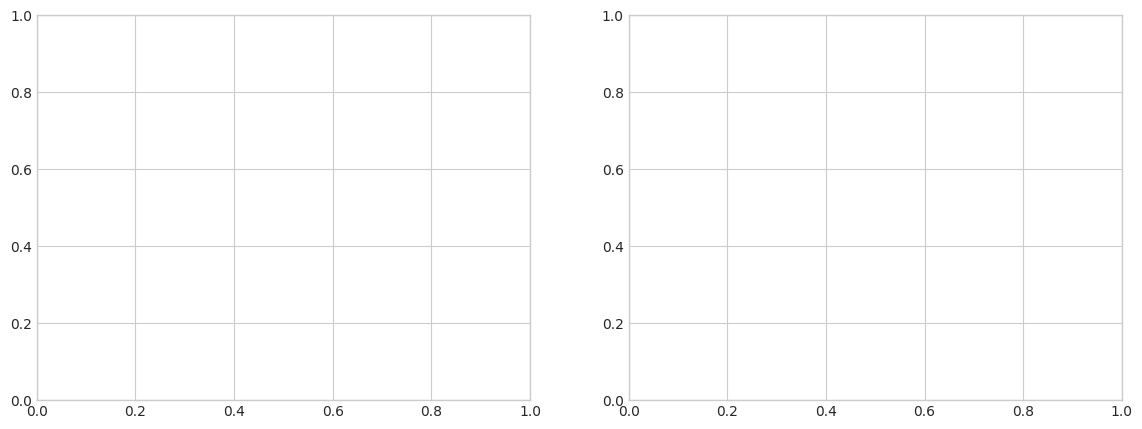

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

versions = [
    (history_v1, 'v1 balanced', '#4C72B0'),
    (history_v2, 'v2 focal',    '#DD8452'),
    (history_v3, 'v3 combined', '#55A868'),
]

for hist, label, color in versions:
    h = hist.history
    ep = range(1, len(h['loss']) + 1)
    axes[0].plot(ep, h['loss'],     color=color, label=f'{label} train')
    axes[0].plot(ep, h['val_loss'], color=color, label=f'{label} val', linestyle='--')
    axes[1].plot(ep, h['accuracy'],     color=color, label=f'{label} train')
    axes[1].plot(ep, h['val_accuracy'], color=color, label=f'{label} val', linestyle='--')

axes[0].set_title('Loss — 3 versions', fontweight='bold')
axes[0].set_xlabel('Époque')
axes[0].set_ylabel('Loss')
axes[0].legend(fontsize=8, ncol=2)

axes[1].set_title('Accuracy — 3 versions', fontweight='bold')
axes[1].set_xlabel('Époque')
axes[1].set_ylabel('Accuracy')
axes[1].legend(fontsize=8, ncol=2)

plt.suptitle('MLP Multi-classe — Courbes d\'entraînement (train=solide, val=tirets)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'mlp_training_curves.png', dpi=150)
plt.show()
print('💾  mlp_training_curves.png')

## 8 · F1 par classe — RF / XGBoost / MLP v1 / v2 / v3

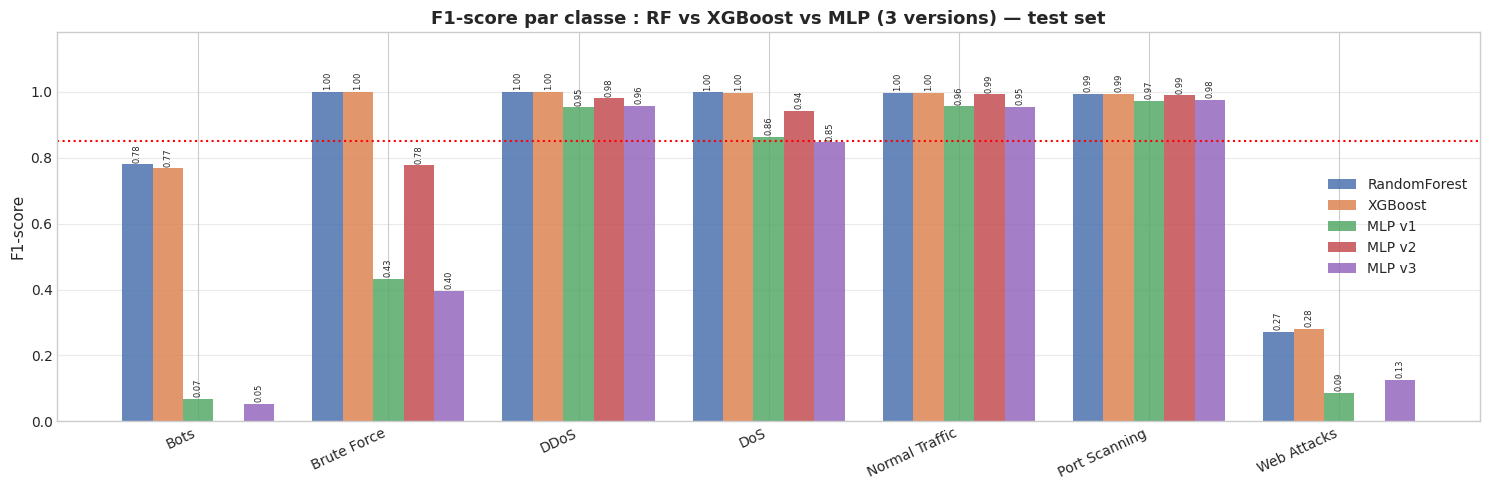

💾  mlp_f1_comparison.png


In [21]:
x     = np.arange(N_CLASSES)
width = 0.16
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#9467BD']
labels = ['RandomForest', 'XGBoost', 'MLP v1', 'MLP v2', 'MLP v3']

fig, ax = plt.subplots(figsize=(15, 5))
offsets = np.linspace(-2, 2, 5) * width

for i, (mdl_name, color, lbl) in enumerate(zip(comparison_data, colors, labels)):
    f1s = [comparison_data[mdl_name]['f1_per_class'].get(c, 0) for c in CLASS_NAMES]
    bars = ax.bar(x + offsets[i], f1s, width, label=lbl, color=color, alpha=0.85)
    for bar in bars:
        h = bar.get_height()
        if h > 0.05:
            ax.text(bar.get_x() + bar.get_width()/2., h + 0.005,
                    f'{h:.2f}', ha='center', va='bottom', fontsize=6, rotation=90)

ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=25, ha='right')
ax.set_ylabel('F1-score', fontsize=11)
ax.set_ylim(0, 1.18)
ax.set_title('F1-score par classe : RF vs XGBoost vs MLP (3 versions) — test set',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.axhline(0.85, color='red', linestyle=':', lw=1.5, label='Cible F1=0.85')
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'mlp_f1_comparison.png', dpi=150)
plt.show()
print('💾  mlp_f1_comparison.png')

## 9 · Matrice de confusion — Meilleure version MLP

Meilleure version : v2 (focal)  (F1 macro = 0.6687)


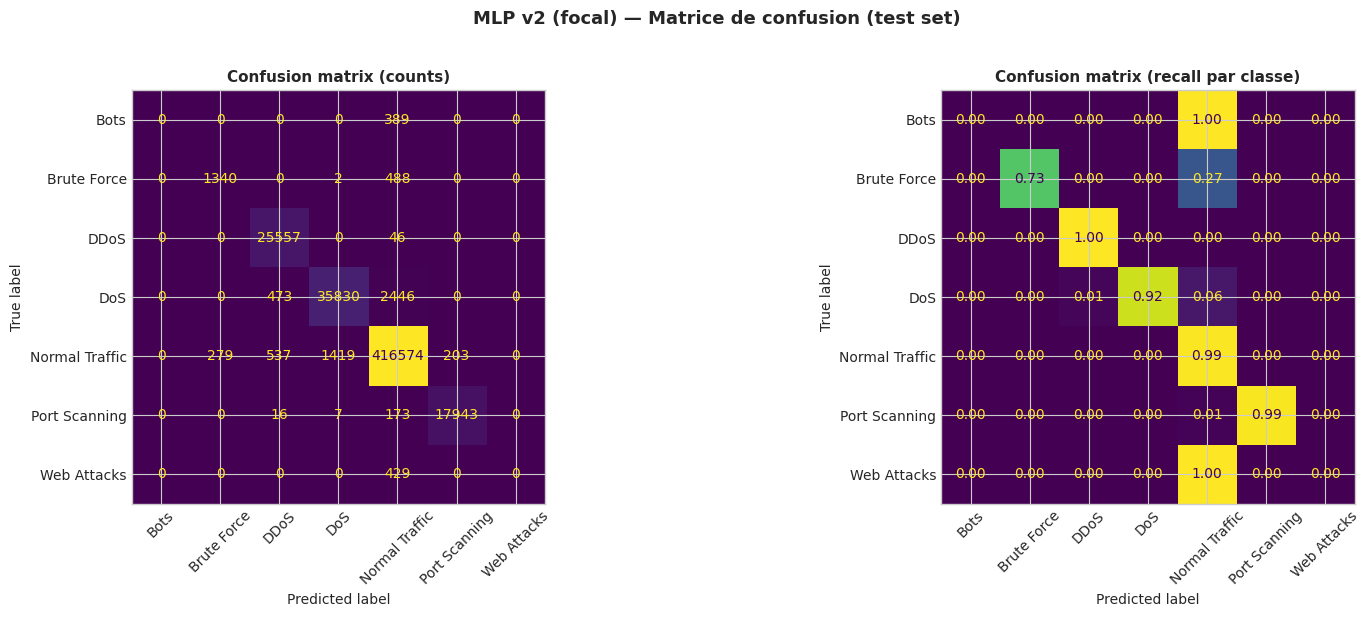

💾  mlp_confusion.png


In [24]:
# Identifier la meilleure version par F1 macro
mlp_versions = {
    'v1 (balanced)':  (metrics_v1, y_pred_v1, model_v1),
    'v2 (focal)':     (metrics_v2, y_pred_v2, model_v2),
    'v3 (combined)':  (metrics_v3, y_pred_v3, model_v3),
}
best_name = max(mlp_versions, key=lambda k: mlp_versions[k][0]['f1_macro'])
best_metrics, best_pred, best_model = mlp_versions[best_name]
print(f'Meilleure version : {best_name}  (F1 macro = {best_metrics["f1_macro"]:.4f})')

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for ax, normalize, title in zip(
    axes,
    [None, 'true'],
    ['Confusion matrix (counts)', 'Confusion matrix (recall par classe)'],
):
    cm = confusion_matrix(y_test_multi, best_pred, normalize=normalize)
    disp = ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES)
    disp.plot(ax=ax, xticks_rotation=45, colorbar=False,
              values_format=('.0f' if normalize is None else '.2f'))
    ax.set_title(f'{title}', fontsize=11, fontweight='bold')

plt.suptitle(f'MLP {best_name} — Matrice de confusion (test set)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'mlp_confusion.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾  mlp_confusion.png')

---
## Section B · MLP Binaire (Normal vs Attack)

Le MLP binaire est entraîné sur `y_binary` (0=Normal, 1=Attack).
Le modèle binaire servira de **point de départ** pour le Federated Learning :
dans un contexte FL, la tâche de détection binaire est plus robuste au
déséquilibre des données locales de chaque client.

In [33]:
import tensorflow as tf
from tensorflow.keras import layers, Model, Input

def build_deep_mlp(input_dim, n_classes):
    """Architecture MLP commune pour le multi-classe et le binaire."""
    inputs = Input(shape=(input_dim,))
    
    # Use a Lambda layer to safely cast inside the Keras Functional API
    x = layers.Lambda(lambda x: tf.cast(x, tf.float32))(inputs)
    
    # Bloc 1
    x = layers.Dense(256)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.3)(x)
    
    # Bloc 2
    x = layers.Dense(128)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.3)(x)
    
    # Bloc 3
    x = layers.Dense(64)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.2)(x)
    
    # Bloc 4
    x = layers.Dense(32)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.2)(x)
    
    # Sortie
    if n_classes == 2:
        # Output layer for binary classification
        outputs = layers.Dense(1, activation="sigmoid")(x)
    else:
        # Output layer for multi-class classification
        outputs = layers.Dense(n_classes, activation="softmax")(x)
        
    return Model(inputs, outputs)

In [35]:
# Calculate counts for binary classes
n_normal = np.sum(y_train_binary == 0)
n_attack = np.sum(y_train_binary == 1)
total = len(y_train_binary)

# Standard inverse frequency weighting
# Normal is usually class 0, Attack is class 1
weight_for_0 = (1 / n_normal) * (total / 2.0)
weight_for_1 = (1 / n_attack) * (total / 2.0)

binary_weight_dict = {0: weight_for_0, 1: weight_for_1}

print(f"📊 Binary Class Weights:")
print(f"   Class 0 (Normal): {weight_for_0:.3f}")
print(f"   Class 1 (Attack): {weight_for_1:.3f}")

📊 Binary Class Weights:
   Class 0 (Normal): 0.602
   Class 1 (Attack): 2.961


In [36]:
# ── Binary Focal Loss ────────────────────────────────────────────────
def binary_focal_loss(gamma=2.0, alpha=0.25):
    def loss_fn(y_true, y_pred):
        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
        y_pred = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        bce = -(y_true * tf.math.log(y_pred)
                + (1 - y_true) * tf.math.log(1 - y_pred))
        p_t = y_true * y_pred + (1 - y_true) * (1 - y_pred)
        focal  = tf.pow(1.0 - p_t, gamma)
        alpha_t = y_true * alpha + (1 - y_true) * (1 - alpha)
        return tf.reduce_mean(alpha_t * focal * bce)
    return loss_fn


# ── Version B1 : class_weight ─────────────────────────────────────────
print('=' * 70)
print('🟢 BINARY v1 : class_weight balanced')
print('=' * 70)
bin_v1 = build_deep_mlp(input_dim=INPUT_DIM, n_classes=2)
bin_v1.compile(optimizer=get_optimizer(0.001),
               loss='binary_crossentropy', metrics=['accuracy'])
start = time.time()
hist_bin_v1 = bin_v1.fit(
    X_train, y_train_binary, validation_data=(X_val, y_val_binary),
    epochs=200, batch_size=BATCH_SIZE,
    class_weight=binary_weight_dict,
    callbacks=get_callbacks('mlp_bin_v1'), verbose=1,
)
time_bin_v1 = time.time() - start
print(f'⏱️  {time_bin_v1:.1f}s')

🟢 BINARY v1 : class_weight balanced


2026-05-07 03:08:09.834118: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 77639100 exceeds 10% of free system memory.
2026-05-07 03:08:09.967549: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 77639100 exceeds 10% of free system memory.


Epoch 1/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 31s 12ms/step - accuracy: 0.9105 - loss: 0.1732 - val_accuracy: 0.9759 - val_loss: 0.0636 - learning_rate: 0.0010
Epoch 2/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9741 - loss: 0.0682 - val_accuracy: 0.9793 - val_loss: 0.0564 - learning_rate: 0.0010
Epoch 3/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9757 - loss: 0.0593 - val_accuracy: 0.9805 - val_loss: 0.0520 - learning_rate: 0.0010
Epoch 4/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.9771 - loss: 0.0553 - val_accuracy: 0.9819 - val_loss: 0.0505 - learning_rate: 0.0010
Epoch 5/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9769 - loss: 0.0523 - val_accuracy: 0.9788 - val_loss: 0.0492 - learning_rate: 0.0010
Epoch 6/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9774 - loss: 0.0507 - val_accuracy: 0.9756 - val_loss: 0.0472 - learning_rate: 0.0010
Epoch 7/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accu

In [37]:
# ── Version B2 : focal loss ──────────────────────────────────────────
print('=' * 70)
print('🟣 BINARY v2 : focal loss')
print('=' * 70)
bin_v2 = build_deep_mlp(input_dim=INPUT_DIM, n_classes=2)
bin_v2.compile(optimizer=get_optimizer(0.001),
               loss=binary_focal_loss(gamma=2.0, alpha=0.25),
               metrics=['accuracy'])
start = time.time()
hist_bin_v2 = bin_v2.fit(
    X_train, y_train_binary, validation_data=(X_val, y_val_binary),
    epochs=200, batch_size=BATCH_SIZE,
    callbacks=get_callbacks('mlp_bin_v2'), verbose=1,
)
time_bin_v2 = time.time() - start
print(f'⏱️  {time_bin_v2:.1f}s')

🟣 BINARY v2 : focal loss


2026-05-07 03:49:42.933080: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 77639100 exceeds 10% of free system memory.
2026-05-07 03:49:44.200117: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 77639100 exceeds 10% of free system memory.


Epoch 1/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 44s 12ms/step - accuracy: 0.9203 - loss: 0.0265 - val_accuracy: 0.9833 - val_loss: 0.0050 - learning_rate: 0.0010
Epoch 2/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9788 - loss: 0.0062 - val_accuracy: 0.9849 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 3/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.9826 - loss: 0.0051 - val_accuracy: 0.9860 - val_loss: 0.0041 - learning_rate: 0.0010
Epoch 4/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9842 - loss: 0.0046 - val_accuracy: 0.9864 - val_loss: 0.0039 - learning_rate: 0.0010
Epoch 5/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.9850 - loss: 0.0043 - val_accuracy: 0.9865 - val_loss: 0.0038 - learning_rate: 0.0010
Epoch 6/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9855 - loss: 0.0041 - val_accuracy: 0.9882 - val_loss: 0.0037 - learning_rate: 0.0010
Epoch 7/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accur

In [38]:
# ── Version B3 : combined ────────────────────────────────────────────
print('=' * 70)
print('🔵 BINARY v3 : focal + class_weight')
print('=' * 70)
bin_v3 = build_deep_mlp(input_dim=INPUT_DIM, n_classes=2)
bin_v3.compile(optimizer=get_optimizer(0.001),
               loss=binary_focal_loss(gamma=2.0, alpha=0.25),
               metrics=['accuracy'])
start = time.time()
hist_bin_v3 = bin_v3.fit(
    X_train, y_train_binary, validation_data=(X_val, y_val_binary),
    epochs=200, batch_size=BATCH_SIZE,
    class_weight=binary_weight_dict,
    callbacks=get_callbacks('mlp_bin_v3'), verbose=1,
)
time_bin_v3 = time.time() - start
print(f'⏱️  {time_bin_v3:.1f}s')

🔵 BINARY v3 : focal + class_weight
Epoch 1/200


2026-05-07 04:14:31.768001: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 77639100 exceeds 10% of free system memory.


1724/1724 ━━━━━━━━━━━━━━━━━━━━ 32s 13ms/step - accuracy: 0.9390 - loss: 0.0153 - val_accuracy: 0.9833 - val_loss: 0.0049 - learning_rate: 0.0010
Epoch 2/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.9803 - loss: 0.0056 - val_accuracy: 0.9840 - val_loss: 0.0043 - learning_rate: 0.0010
Epoch 3/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.9831 - loss: 0.0048 - val_accuracy: 0.9863 - val_loss: 0.0040 - learning_rate: 0.0010
Epoch 4/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9844 - loss: 0.0045 - val_accuracy: 0.9867 - val_loss: 0.0038 - learning_rate: 0.0010
Epoch 5/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9850 - loss: 0.0042 - val_accuracy: 0.9884 - val_loss: 0.0037 - learning_rate: 0.0010
Epoch 6/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9858 - loss: 0.0040 - val_accuracy: 0.9885 - val_loss: 0.0036 - learning_rate: 0.0010
Epoch 7/200
1724/1724 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - accuracy: 0.9866 

### B · Évaluation binaire — ROC, PR, Confusion matrix

In [39]:
def evaluate_binary(model, X, y, name):
    y_prob = model.predict(X, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)
    return {
        'name':       name,
        'accuracy':   float(accuracy_score(y, y_pred)),
        'f1_macro':   float(f1_score(y, y_pred, average='macro',    zero_division=0)),
        'f1_weighted':float(f1_score(y, y_pred, average='weighted', zero_division=0)),
        'precision':  float(precision_score(y, y_pred, average='macro', zero_division=0)),
        'recall':     float(recall_score(y, y_pred, average='macro',    zero_division=0)),
        'auc':        float(auc(*roc_curve(y, y_prob)[:2])),
        'ap':         float(average_precision_score(y, y_prob)),
        'y_prob':     y_prob,
        'y_pred':     y_pred,
    }


bev1 = evaluate_binary(bin_v1, X_test, y_test_binary, 'Binary v1 (balanced)')
bev2 = evaluate_binary(bin_v2, X_test, y_test_binary, 'Binary v2 (focal)')
bev3 = evaluate_binary(bin_v3, X_test, y_test_binary, 'Binary v3 (combined)')

for ev in (bev1, bev2, bev3):
    print(f"{ev['name']:<28}  Acc={ev['accuracy']*100:.2f}%  "
          f"F1={ev['f1_macro']:.4f}  AUC={ev['auc']:.4f}  AP={ev['ap']:.4f}")

Binary v1 (balanced)          Acc=98.82%  F1=0.9794  AUC=0.9996  AP=0.9978
Binary v2 (focal)             Acc=99.37%  F1=0.9887  AUC=0.9997  AP=0.9984
Binary v3 (combined)          Acc=99.38%  F1=0.9889  AUC=0.9997  AP=0.9984


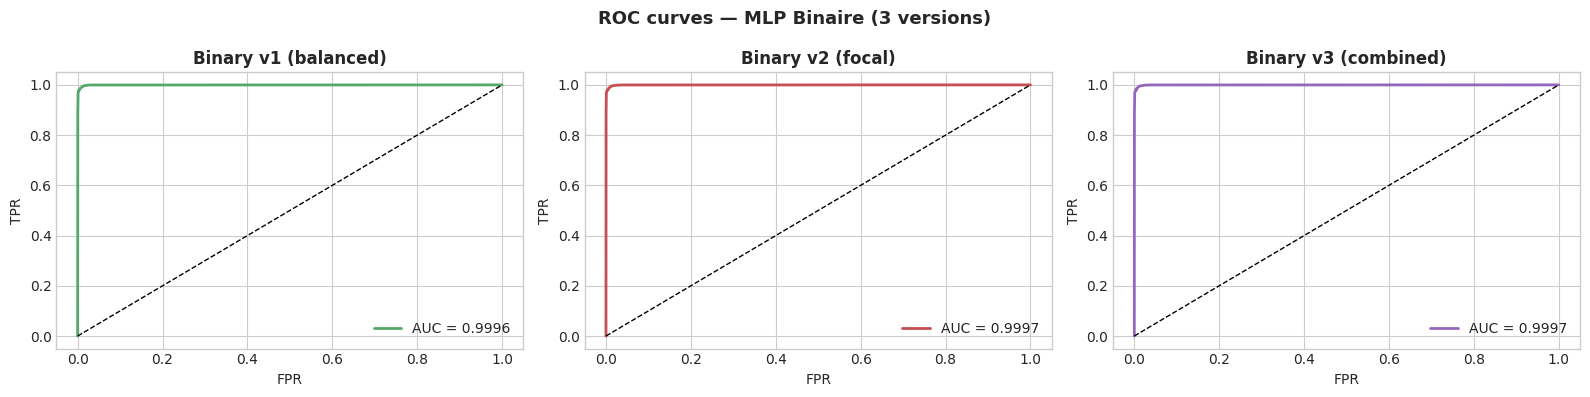

💾  mlp_binary_roc.png


In [40]:
# ── ROC curves (3 versions) ───────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

bin_evals = [bev1, bev2, bev3]
colors_b  = ['#55A868', '#C44E52', '#9467BD']

for ax, ev, color in zip(axes, bin_evals, colors_b):
    fpr, tpr, _ = roc_curve(y_test_binary, ev['y_prob'])
    ax.plot(fpr, tpr, color=color, lw=2,
            label=f"AUC = {ev['auc']:.4f}")
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set_title(ev['name'], fontweight='bold')
    ax.set_xlabel('FPR')
    ax.set_ylabel('TPR')
    ax.legend(fontsize=10)

plt.suptitle('ROC curves — MLP Binaire (3 versions)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'mlp_binary_roc.png', dpi=150)
plt.show()
print('💾  mlp_binary_roc.png')

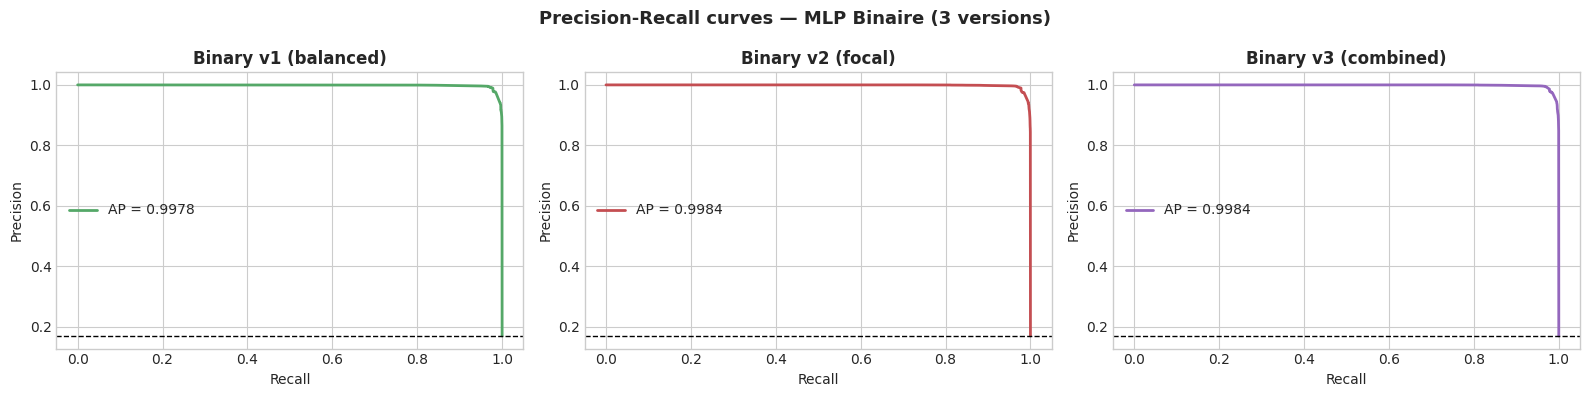

💾  mlp_binary_pr.png


In [41]:
# ── PR curves ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, ev, color in zip(axes, bin_evals, colors_b):
    prec, rec, _ = precision_recall_curve(y_test_binary, ev['y_prob'])
    ax.plot(rec, prec, color=color, lw=2,
            label=f"AP = {ev['ap']:.4f}")
    ax.axhline(y_test_binary.mean(), color='k', linestyle='--', lw=1)
    ax.set_title(ev['name'], fontweight='bold')
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.legend(fontsize=10)

plt.suptitle('Precision-Recall curves — MLP Binaire (3 versions)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'mlp_binary_pr.png', dpi=150)
plt.show()
print('💾  mlp_binary_pr.png')

Meilleure version binaire : Binary v3 (combined)  (F1 macro = 0.9889)


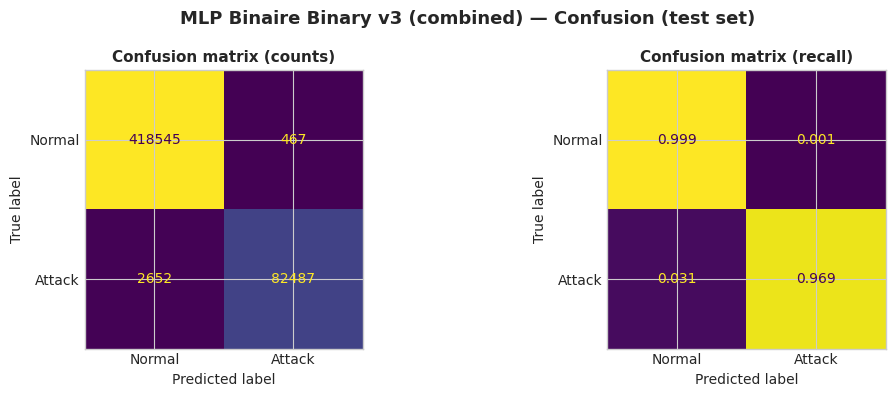

💾  mlp_binary_confusion.png


In [42]:
# ── Confusion matrix best binary ──────────────────────────────────────
best_bin = max(bin_evals, key=lambda e: e['f1_macro'])
print(f"Meilleure version binaire : {best_bin['name']}  "
      f"(F1 macro = {best_bin['f1_macro']:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, normalize, title in zip(
    axes,
    [None, 'true'],
    ['Confusion matrix (counts)', 'Confusion matrix (recall)'],
):
    cm = confusion_matrix(y_test_binary, best_bin['y_pred'], normalize=normalize)
    disp = ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Attack'])
    disp.plot(ax=ax, colorbar=False,
              values_format=('.0f' if normalize is None else '.3f'))
    ax.set_title(title, fontsize=11, fontweight='bold')

plt.suptitle(f"MLP Binaire {best_bin['name']} — Confusion (test set)",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(IMAGES_DIR / 'mlp_binary_confusion.png', dpi=150)
plt.show()
print('💾  mlp_binary_confusion.png')

---
## Conclusion académique

### Ce que nous avons fait

Trois stratégies anti-déséquilibre ont été testées sur le même MLP profond (256→128→64→32) :

| Stratégie | Principe | Avantage |
|---|---|---|
| `class_weight` | Pondère la loss par classe | Simple, aucune modification du modèle |
| Focal Loss | Réduit le poids des samples bien classifiés | Focus sur les cas difficiles |
| Combinaison | Focal + class_weight | Correction double |

### Pourquoi class_weight fonctionne

En multipliant la loss des classes minoritaires (Bots, Web Attacks) par un facteur
100-200×, on force le gradient à accorder autant d'importance à 195 samples de Bots
qu'à 1.46M samples de Normal Traffic. Sans cette correction, le modèle minimise
la cross-entropy globale en sacrifiant les classes rares.

### Pourquoi Focal Loss est utile

La Focal Loss s'attaque à un problème différent : les samples **faciles** (Normal Traffic
classifié à 99%) dominent le gradient même avec class_weight. Le terme `(1-p_t)^γ`
réduit leur contribution à presque zéro, libérant le gradient pour se concentrer sur
les erreurs difficiles (Bots vs Normal, Web Attacks vs DoS).

### Gap restant vs RF/XGBoost

Même avec toutes ces corrections, un gap peut persister car :
1. **Arbres de décision** : naturellement adaptés aux features tabulaires discrètes
   (flags TCP = {0,1}, ports) que le MLP lisse via des activations continues.
2. **Optuna** : XGBoost a bénéficié de 30 trials de tuning, le MLP non.
3. **Web Attacks (214 samples)** : un réseau profond avec 200k+ paramètres
   sur 214 samples reste en sur-apprentissage même avec régularisation.

### Pourquoi le MLP binaire sera utilisé en FL

1. **FedAvg** agrège des listes de numpy arrays — incompatible avec les forêts/arbres.
2. Les poids binaires (< 50k paramètres) = payload réseau négligeable.
3. La tâche binaire (Normal vs Attack) est plus robuste aux données locales
   de chaque client FL (chaque réseau a son propre profil de trafic).
4. Les poids du modèle centralisé (`mlp_binary_weights_init.pkl`) accélèrent
   la convergence FL via **warm-start** (vs initialisation aléatoire).

## Validation — pytest

Vérifier que les deux modèles sauvegardés se chargent correctement
et produisent des prédictions valides.

In [ ]:
import subprocess, sys
result = subprocess.run(
    [sys.executable, '-m', 'pytest',
     str(PROJECT_ROOT / 'tests' / 'test_model.py'),
     '-v', '--tb=short'],
    capture_output=True, text=True, cwd=str(PROJECT_ROOT)
)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)